# Sampler interface

Run from the repository root using the `.venv/bin/python` kernel. Select a paired mock, run Cobaya, then plot the saved chain.

## Import packages

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from chainconsumer import Chain, ChainConsumer, PlotConfig, Truth
from cobaya.run import run
from likelihood import DDRlike
from tools.utilities import Utilities

green        = ['#a6dba0','#5aae61','#1b7837']
purple       = ['#c2a5cf', '#9970ab', '#762a83']
analogous    = ['#a0c3db', '#dbb7a0']
warm         = ['#fdcc8a', '#fc8d59', '#d7301f']
cool         = ['#41b6c4', '#2c7fb8', '#253494']

# plt.rcParams.update({'text.usetex': False, 'font.family': 'serif'})

plt.style.use('sanglier')

## Select the mock

Paste the NPZ path printed by the mock notebook. Model and injected parameters are read from its metadata.

In [2]:
# mock_file = Path('mock_data/lusso2020_flux_table/current_sarm/random_seed27/M1alpha-0.075beta0.0nQSO200_paired_dataset.npz')

# mock_file = Path('mock_data/lusso2020_flux_table/current_sarm/random_seed27/M2alpha-0.07beta-0.014nQSO2000_paired_dataset.npz')

# mock_file = Path('mock_data/lusso2020_flux_table/current_sarm/asimov_seed27/M2alpha-0.07beta-0.014nQSO200_paired_dataset.npz')

# mock_file = Path('mock_data/lusso2020_flux_table/current_sarm/asimov_seed27/M1alpha-0.075beta-0.014nQSO10000_paired_dataset.npz')

# Fig. 1: run once for each scenario: 'current', 'future', 'targeted'
scenario = 'current'
mock_file = Path(f'mock_data/M2alpha-0.07beta-0.014nQSO1000_{scenario}_paired_dataset.npz')

if not mock_file.is_file():
    raise FileNotFoundError(f'Generate this mock first: {mock_file}')
prefix = mock_file.with_name(mock_file.name.removesuffix('_paired_dataset.npz'))
metadata = json.loads(Path(str(prefix) + '_metadata.json').read_text())
dataset = {**metadata['ddr'], 'settings': str(prefix.relative_to('mock_data'))}
print(dataset)

{'model': 'M2', 'alpha': -0.07, 'beta': -0.014, 'settings': 'M2alpha-0.07beta-0.014nQSO1000_current'}


## Configure the sampler

Broad priors keep the small-sample contours away from the old narrow bounds; non-positive eta is rejected by the likelihood. Check for prior-edge effects in the resulting plots. Set `resume=True` only to continue an existing run on the same mock.

In [ ]:
resume = False

info = Utilities.sampler_config(dataset, DDRlike)
priors = {'alpha': {'min': -0.9, 'max': 1.5},
          'beta': {'min': -1.0, 'max': 1.0}}
for parameter in info['params']:
    info['params'][parameter]['prior'] = priors[parameter]
    info['params'][parameter]['proposal'] = 0.03

info['sampler']['mcmc'].update({
    'burn_in': 200,
    'Rminus1_stop': 0.01,
    'Rminus1_cl_stop': 0.05,
})
info['force'] = True
info['resume'] = resume
info['debug'] = False
Path(info['output']).parent.mkdir(parents=True, exist_ok=True)
print('Chain output:', info['output'])

## Run Cobaya

Let the run finish with “The run has converged” before using the contours.

In [ ]:
updated_info, sampler = run(info)

## Plot the saved chain

Discard the first 30% of saved rows from each chain and retain Cobaya's sample weights.

In [ ]:
chain_root = Path(info['output'])
burn_fraction = 0.3
parameters = list(info['params'])
labels = {'alpha': r'$\alpha_0$', 'beta': r'$\alpha_1$'}

frames = []
for path in sorted(chain_root.parent.glob(chain_root.name + '.[0-9]*.txt')):
    with path.open() as handle:
        columns = handle.readline().lstrip('#').split()
    frame = pd.read_csv(path, sep=r'\s+', comment='#', names=columns)
    frames.append(frame.iloc[int(burn_fraction * len(frame)):])
if not frames:
    raise FileNotFoundError(f'No chain files for {chain_root}')
samples = pd.concat(frames, ignore_index=True)

c = ChainConsumer()
c.add_chain(Chain(samples=samples[parameters + ['weight']],
                  weight_column='weight', name=f"N = {metadata['specifications']['n_QSO']}",
                  color=cool[1],
                  shade_gradient = 0.8, linewidth=3.0,
                  bins=10,
                  smooth=20))
c.add_truth(Truth(location={p: dataset[p] for p in parameters}, color='k'))
c.set_plot_config(PlotConfig(labels=labels, usetex=True, serif=True, summarise=True))
fig = c.plotter.plot(figsize=(3.4, 3.0) if len(parameters) == 1 else (6, 6))
plt.tight_layout()
# plt.savefig('/home/nataliehogg/Documents/Projects/davide/figures/current_M1.pdf', dpi=300)
plt.show()
print(c.analysis.get_summary())

In [ ]:
fig = c.plotter.plot_walks(convolve=100)
plt.show()

### Compare results

In [3]:
# chain_dir = Path('chains/lusso2020_flux_table/current_sarm/random_seed27')
# chains = {
#     'N = 50': 'M1alpha-0.075beta0.0nQSO50',
#     'N = 100': 'M1alpha-0.075beta0.0nQSO100',
#     'N = 200': 'M1alpha-0.075beta0.0nQSO200',
#     'N = 2000': 'M1alpha-0.075beta0.0nQSO2000',
# }

# chain_dir = Path('chains/lusso2020_flux_table/current_sarm/asimov_seed27')
# chains = {
#     'N = 4': 'M1alpha-0.075beta-0.014nQSO4',
#     'N = 100': 'M1alpha-0.075beta-0.014nQSO100',
#     'N = 1000': 'M1alpha-0.075beta-0.014nQSO1000',
#     'N = 10000': 'M1alpha-0.075beta-0.014nQSO10000',
# }
# colours = {
#     'N = 4': warm[0],
#     'N = 100': warm[1],
#     'N = 1000': warm[2],
#     'N = 10000': purple[2]
# }

chain_dir = Path('chains')
chains = {
    'Current':      'M2alpha-0.07beta-0.014nQSO1000_current',
    'Intermediate': 'M2alpha-0.07beta-0.014nQSO1000_future',
    'Optimistic':   'M2alpha-0.07beta-0.014nQSO1000_targeted',
}
colours = {
    'Current':      warm[1],
    'Intermediate': warm[2],
    'Optimistic':   purple[2]
}
truth_m1 = {'alpha': -0.075}
truth_m2 = {'alpha': -0.070, 'beta': -0.014}
burn_fraction = 0.3
figure_root = Path('results/baseline_M2_comparison')

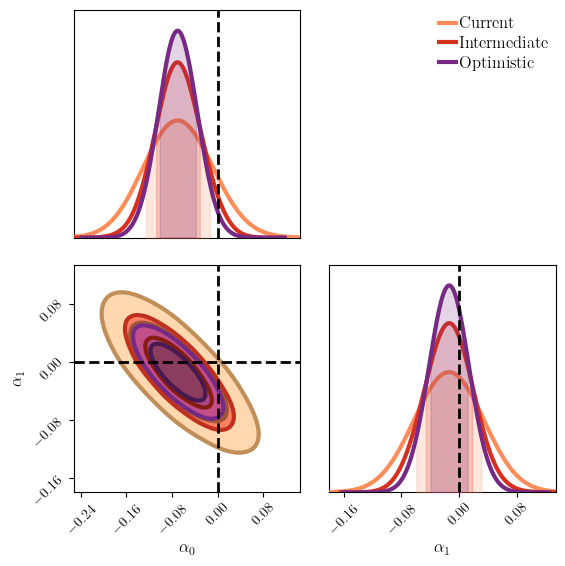

In [4]:
parameters = list(truth_m2)
c = ChainConsumer()
for name, stem in chains.items():
    chain_root = chain_dir / stem
    frames = []
    for path in sorted(chain_root.parent.glob(chain_root.name + '.[0-9]*.txt')):
        with path.open() as handle:
            columns = handle.readline().lstrip('#').split()
        frame = pd.read_csv(path, sep=r'\s+', comment='#', names=columns)
        frames.append(frame.iloc[int(burn_fraction * len(frame)):])
    if not frames:
        raise FileNotFoundError(f'No chain files for {chain_root}')
    samples = pd.concat(frames, ignore_index=True)
    
    c.add_chain(Chain(samples=samples[parameters + ['weight']],
                      weight_column='weight', name=name,
                      color = colours[name],
                      bins=10, smooth=20, shade_gradient = 0.8, linewidth=3.0,
                      sigmas=[0, 1, 2]))

c.add_truth(Truth(location={'alpha': 0.0, 'beta': 0.0}, color='k', line_style='--', line_width=2.0))
c.set_plot_config(PlotConfig( 
    labels={'alpha': r'$\alpha_0$', 'beta': r'$\alpha_1$'},
    usetex=True, serif=True, legend_color_text=False, 
    # extents={'alpha':(-0.15, 0.15)}
))
fig = c.plotter.plot(figsize=(3.4, 3.0) if len(parameters) == 1 else (6, 6),)
plt.tight_layout()
plt.savefig('results/comparison_M2_N1000.pdf', dpi=300)
plt.show()